In [ ]:
!pip install roboflow

In [ ]:
from pathlib import Path
from google.colab import userdata
from roboflow import Roboflow

project_folder = Path("/content/ODOL")

raw_dataset_folder = project_folder / "dataset" / "raw"
results_folder = project_folder / "results"

raw_dataset_folder.mkdir(parents=True, exist_ok=True)
results_folder.mkdir(parents=True, exist_ok=True)

ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

project = rf.workspace("sigara-hpnoo").project("truck-over-dimension-brupr")

dataset = project.version(2).download("yolov8",location="/content/ODOL/dataset/raw/truck-over-dimension")

source_dataset = Path(dataset.location)

source_dataset

loading Roboflow workspace...
loading Roboflow project...


PosixPath('/content/ODOL/dataset/raw/truck-over-dimension')

In [ ]:
import yaml

data_yaml = source_dataset / "data.yaml"

data = yaml.safe_load(data_yaml.read_text())
class_names = data["names"]

class_names

['NOT ODOL', 'ODOL']

In [ ]:
image_label_pairs = []

for split_name in ["train","valid","test"]:
    image_folder = source_dataset / split_name / "images"
    label_folder = source_dataset / split_name / "labels"

    for image_file in sorted(image_folder.glob("*.jpg")):
        label_file = label_folder / f"{image_file.stem}.txt"
        image_label_pairs.append((split_name,image_file,label_file))

len(image_label_pairs)

2853

In [ ]:
image_groups = {}

for split_name,image_file,label_file in image_label_pairs:
    original_name = image_file.stem.split(".rf.")[0]

    if original_name not in image_groups:
        image_groups[original_name] = []

    image_groups[original_name].append((split_name,image_file,label_file))

len(image_groups)

1095

In [ ]:
groups_in_multiple_splits = 0

for group_items in image_groups.values():
    split_names = {item[0] for item in group_items}

    if len(split_names) > 1:
        groups_in_multiple_splits += 1

groups_in_multiple_splits

0

In [ ]:
split_name,image_file,label_file = image_label_pairs[0]

label_file.read_text()

'1 0.770855090625 1 0.7769230765625 0.9827849000000001 0.784615384375 0.8156837609375 0.79076923125 0.43600284843750003 0.7769230765625 0.3827849 0.7184615390625 0.2997535609375 0.684615384375 0.28299857500000003 0.5538461531250001 0.27371794843749997 0.466153846875 0.276670940625 0.4523076921875 0.2884529921875 0.455384615625 0.6336125359375 0.48 0.7123888890625001 0.49230769218750003 0.890527065625 0.5323076921875 0.9326011390625 0.5422426734375 1 0.770855090625 1\n1 0.45846153906250003 0.041272079687500005 0.3476923078125 0.045528490625 0.33999999999999997 0.0551296296875 0.3369230765625 0.0849700859375 0.3369230765625 0.19997008593750001 0.36307692343750003 0.4638262109375 0.3769230765625 0.48454415937500006 0.3815384609375 0.514783475 0.45076923124999996 0.52087321875 0.4569230765625 0.5061923078125 0.455384615625 0.3146125359375 0.48923076875 0.277867521875 0.5523076921875 0.2711381765625 0.54923076875 0.1184786328125 0.5076923078125 0.05132478593749999 0.45846153906250003 0.0412

In [ ]:
import cv2
import shutil

crop_dataset = project_folder / "dataset" / "mobilenet"

shutil.rmtree(crop_dataset,ignore_errors=True)

for split_name,image_file,label_file in image_label_pairs:
    image = cv2.imread(image_file)
    height,width = image.shape[:2]

    for crop_number,line in enumerate(label_file.read_text().splitlines()):
        parts = line.split()
        class_id = int(parts[0])

        if len(parts) == 5:
            center_x,center_y,box_width,box_height = [float(value) for value in parts[1:]]

            x1 = int((center_x - box_width / 2) * width)
            y1 = int((center_y - box_height / 2) * height)
            x2 = int((center_x + box_width / 2) * width)
            y2 = int((center_y + box_height / 2) * height)

        else:
            x_values = [float(parts[index]) for index in range(1,len(parts),2)]
            y_values = [float(parts[index]) for index in range(2,len(parts),2)]

            x1 = int(min(x_values) * width)
            y1 = int(min(y_values) * height)
            x2 = int(max(x_values) * width)
            y2 = int(max(y_values) * height)

        x1 = max(0,min(x1,width))
        y1 = max(0,min(y1,height))
        x2 = max(0,min(x2,width))
        y2 = max(0,min(y2,height))

        class_folder = crop_dataset / split_name / class_names[class_id].replace(" ","_")
        class_folder.mkdir(parents=True,exist_ok=True)

        crop = image[y1:y2,x1:x2]
        crop_path = class_folder / f"{image_file.stem}_{crop_number}.jpg"

        cv2.imwrite(crop_path,crop)

crop_dataset

PosixPath('/content/ODOL/dataset/mobilenet')

In [ ]:
for split_name in ["train","valid","test"]:
    print(split_name)

    for class_name in class_names:
        class_folder = crop_dataset / split_name / class_name.replace(" ","_")
        crop_count = len(list(class_folder.glob("*.jpg")))

        print(class_name,crop_count)

train
NOT ODOL 1191
ODOL 936
valid
NOT ODOL 72
ODOL 64
test
NOT ODOL 16
ODOL 25


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_data = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

valid_data = ImageDataGenerator(preprocessing_function=preprocess_input)
test_data = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_data.flow_from_directory(
    crop_dataset / "train",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=True,
    seed=42
)

valid_generator = valid_data.flow_from_directory(
    crop_dataset / "valid",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

test_generator = test_data.flow_from_directory(
    crop_dataset / "test",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

train_generator.class_indices

Found 2127 images belonging to 2 classes.
Found 136 images belonging to 2 classes.
Found 41 images belonging to 2 classes.


{'NOT_ODOL': 0, 'ODOL': 1}

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D,Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
output = Dense(1,activation="sigmoid")(x)

model = Model(inputs=base_model.input,outputs=output)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

final_model_path = (
    results_folder
    / "mobilenet_odol_classifier.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=15,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        filepath=final_model_path,
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    train_generator,
    epochs=100,
    validation_data=valid_generator,
    callbacks=callbacks
)

Epoch 1/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 79s 879ms/step - accuracy: 0.6695 - loss: 0.6134 - val_accuracy: 0.7206 - val_loss: 0.5314
Epoch 2/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 34s 503ms/step - accuracy: 0.7889 - loss: 0.4608 - val_accuracy: 0.7426 - val_loss: 0.4882
Epoch 3/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 31s 461ms/step - accuracy: 0.8284 - loss: 0.4034 - val_accuracy: 0.7574 - val_loss: 0.4563
Epoch 4/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 32s 472ms/step - accuracy: 0.8533 - loss: 0.3688 - val_accuracy: 0.7647 - val_loss: 0.4240
Epoch 5/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 32s 469ms/step - accuracy: 0.8702 - loss: 0.3375 - val_accuracy: 0.7941 - val_loss: 0.3991
Epoch 6/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 30s 448ms/step - accuracy: 0.8773 - loss: 0.3232 - val_accuracy: 0.7721 - val_loss: 0.4133
Epoch 7/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 32s 473ms/step - accuracy: 0.8764 - loss: 0.3111 - val_accuracy: 0.8382 - val_loss: 0.3677
Epoch 8/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 30s 455ms/step - accuracy: 0.8895 - loss: 0.2879 - 

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

test_generator.reset()

predictions = model.predict(test_generator)

y_true = test_generator.classes
y_pred = (predictions > 0.5).astype(int).ravel()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
matrix = confusion_matrix(y_true, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 score:", round(f1, 4))
print("Confusion matrix:")
print(matrix)

2/2 ━━━━━━━━━━━━━━━━━━━━ 18s 13s/step
Accuracy: 0.9024
Precision: 0.8889
Recall: 0.96
F1 score: 0.9231
Confusion matrix:
[[13  3]
 [ 1 24]]


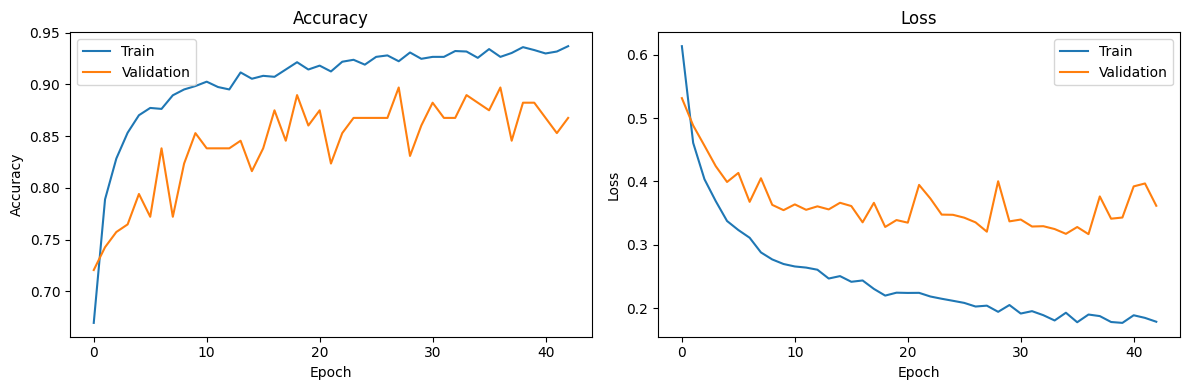

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig(
    "/content/ODOL/results/mobilenet_training_history.png"
)
plt.show()

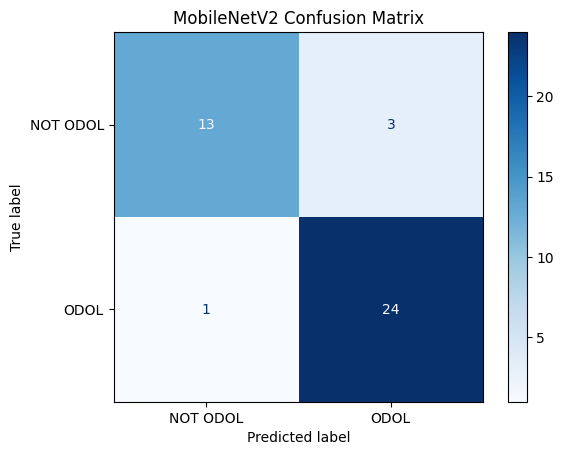

              precision    recall  f1-score   support

    NOT ODOL       0.93      0.81      0.87        16
        ODOL       0.89      0.96      0.92        25

    accuracy                           0.90        41
   macro avg       0.91      0.89      0.89        41
weighted avg       0.90      0.90      0.90        41



In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names
)

display.plot(cmap="Blues", values_format="d")

plt.title("MobileNetV2 Confusion Matrix")
plt.savefig(
    "/content/ODOL/results/mobilenet_confusion_matrix.png"
)
plt.show()

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

In [ ]:
model.save(final_model_path)

final_model_path

PosixPath('/content/ODOL/results/mobilenet_odol_classifier.keras')

In [ ]:
from tensorflow.keras.models import load_model

classifier_model = load_model(final_model_path)

classifier_model

<Functional name=functional, built=True>

In [ ]:
from google.colab import files

files.download("/content/ODOL/results/mobilenet_odol_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>